In [1]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:

import os

drive_path = "/content/drive/MyDrive"

print(os.listdir(drive_path))


['Colab Notebooks', 'Ro', 'Classroom', 'Video', 'signal-2024-06-12-20-42-19-255.jpg', '4.pdf', '6.pdf', '7.pdf', '1.pdf', '12.pdf', '5.pdf', '2.pdf', '8.pdf', '11.pdf', '3.pdf', '9.pdf', 'NTT final.mp4', 'lv_0_20241022191739.mp4', 'WhatsApp Image 2025-05-11 at 22.46.43_511b076c.jpg', 'Joe Austin Martin (RA2311026050032)', 'DBMS with MYSQl (1).pdf', 'UHV_II_Reflection_RA2311026050032.pdf', 'Certificate prodigy.pdf', 'IMG-20250619-WA0010 (2).jpg', 'IMG-20250619-WA0010 (1).jpg', 'IMG-20250619-WA0010.jpg', 'DBMS with MYSQl.pdf', 'Data Structure And Algorithm.pdf', 'Screenshot_2025-07-18-21-35-20-09_40deb401b9ffe8e1df2f1cc5ba480b12.jpg', 'IMG-20250725-WA0030.jpg', 'Resume_JOE (1).pdf', 'SIMULATING TCP CONGESTION CONTROL USING FINITE STATE AUTOMATA', 'RA2311026050032.docx', 'Resume_Skill_Matching_System (1).pdf', 'Screenshot 2025-08-28 194620.png', 'Comparison of Model Approaches for my project don....gsheet', 'Aadhar card.pdf', 'cnai task4.pdf', 'IMG-20251014-WA0030.jpg', 'Screenshot_2025-1

In [3]:

import os

drive_path = "/content/drive/MyDrive"

print(os.listdir(drive_path))


['Colab Notebooks', 'Classroom', 'archive.zip']


In [4]:

import os

zip_path = "/content/drive/MyDrive/archive.zip"

if os.path.exists(zip_path):
    print("ZIP file found!")
    print(f"File size: {os.path.getsize(zip_path) / (1024**2):.2f} MB")
else:
    print("ZIP file not found. Checking My Drive...")
    print(os.listdir("/content/drive/MyDrive"))


ZIP file found!
File size: 219.40 MB


In [5]:

import zipfile
import os

zip_path = "/content/drive/MyDrive/archive.zip"
extract_path = "/content/rice_dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("Main folders:", os.listdir(extract_path))


Dataset extracted successfully!
Main folders: ['Rice_Image_Dataset']


In [6]:

import os

for root, dirs, files in os.walk("/content/rice_dataset"):
    level = root.replace("/content/rice_dataset", "").count(os.sep)
    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")
        if level == 2:
            print("  " * (level + 1) + f"{len(files)} files")


rice_dataset/
  Rice_Image_Dataset/
    Arborio/
      15000 files
    Basmati/
      15000 files
    Ipsala/
      15000 files
    Jasmine/
      15000 files
    Karacadag/
      15000 files


In [7]:

import os
import random
import shutil

random.seed(42)

source_dir = "/content/rice_dataset/Rice_Image_Dataset"
subset_dir = "/content/rice_subset"

classes = ["Arborio", "Basmati", "Ipsala", "Jasmine", "Karacadag"]
images_per_class = 1000

# Create a balanced subset
for rice_class in classes:
    class_path = os.path.join(source_dir, rice_class)
    output_path = os.path.join(subset_dir, rice_class)
    os.makedirs(output_path, exist_ok=True)

    images = [
        f for f in os.listdir(class_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ]

    selected_images = random.sample(
        images, min(images_per_class, len(images))
    )

    for image_name in selected_images:
        shutil.copy2(
            os.path.join(class_path, image_name),
            os.path.join(output_path, image_name)
        )

    print(f"{rice_class}: {len(selected_images)} images")

print("\nBalanced subset created at:", subset_dir)


Arborio: 1000 images
Basmati: 1000 images
Ipsala: 1000 images
Jasmine: 1000 images
Karacadag: 1000 images

Balanced subset created at: /content/rice_subset


In [8]:

for rice_class in classes:
    folder = os.path.join(subset_dir, rice_class)
    count = len(os.listdir(folder))
    print(f"{rice_class}: {count} images")

print("Total images:", sum(
    len(os.listdir(os.path.join(subset_dir, c)))
    for c in classes
))


Arborio: 1000 images
Basmati: 1000 images
Ipsala: 1000 images
Jasmine: 1000 images
Karacadag: 1000 images
Total images: 5000


In [9]:

import tensorflow as tf

data_dir = "/content/rice_subset"
img_size = (224, 224)
batch_size = 32
seed = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=seed,
    image_size=img_size,
    batch_size=batch_size
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=seed,
    image_size=img_size,
    batch_size=batch_size
)

class_names = train_ds.class_names
print("Classes:", class_names)


Found 5000 files belonging to 5 classes.
Using 4000 files for training.
Found 5000 files belonging to 5 classes.
Using 1000 files for validation.
Classes: ['Arborio', 'Basmati', 'Ipsala', 'Jasmine', 'Karacadag']


In [10]:

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

print("Training and testing datasets are ready!")


Training and testing datasets are ready!


In [11]:

import tensorflow as tf
from tensorflow.keras import layers, models

# Optimize data loading
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

# Build CNN model
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.Rescaling(1./255),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(5, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,605 (42.61 MB)

 Trainable params: 11,169,605 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=10,
    callbacks=[early_stop]
)


Epoch 1/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 488s 4s/step - accuracy: 0.8410 - loss: 0.4479 - val_accuracy: 0.9330 - val_loss: 0.1805
Epoch 2/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 485s 4s/step - accuracy: 0.9408 - loss: 0.1820 - val_accuracy: 0.9520 - val_loss: 0.1263
Epoch 3/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 497s 4s/step - accuracy: 0.9473 - loss: 0.1478 - val_accuracy: 0.9570 - val_loss: 0.1266
Epoch 4/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 501s 4s/step - accuracy: 0.9565 - loss: 0.1263 - val_accuracy: 0.9590 - val_loss: 0.1188
Epoch 5/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 497s 4s/step - accuracy: 0.9605 - loss: 0.1122 - val_accuracy: 0.9590 - val_loss: 0.1195
Epoch 6/10
118/125 ━━━━━━━━━━━━━━━━━━━━ 25s 4s/step - accuracy: 0.9630 - loss: 0.0954

KeyboardInterrupt: 

In [13]:

# Use fewer batches per epoch to reduce training time
history_fast = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=3,
    steps_per_epoch=40,
    validation_steps=10,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True
        )
    ]
)


Epoch 1/3
40/40 ━━━━━━━━━━━━━━━━━━━━ 153s 4s/step - accuracy: 0.9703 - loss: 0.0885 - val_accuracy: 0.9594 - val_loss: 0.1396
Epoch 2/3
40/40 ━━━━━━━━━━━━━━━━━━━━ 151s 4s/step - accuracy: 0.9766 - loss: 0.0673 - val_accuracy: 0.9594 - val_loss: 0.1352
Epoch 3/3
40/40 ━━━━━━━━━━━━━━━━━━━━ 205s 5s/step - accuracy: 0.9625 - loss: 0.0973 - val_accuracy: 0.9656 - val_loss: 0.1119


In [14]:

test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

print(f"Full Validation Loss: {test_loss:.4f}")
print(f"Full Validation Accuracy: {test_accuracy * 100:.2f}%")


32/32 ━━━━━━━━━━━━━━━━━━━━ 47s 1s/step - accuracy: 0.9570 - loss: 0.1255
Full Validation Loss: 0.1255
Full Validation Accuracy: 95.70%


32/32 ━━━━━━━━━━━━━━━━━━━━ 40s 1s/step
              precision    recall  f1-score   support

     Arborio     0.1774    0.1746    0.1760       189
     Basmati     0.1827    0.1885    0.1856       191
      Ipsala     0.1852    0.1878    0.1865       213
     Jasmine     0.2332    0.2206    0.2267       204
   Karacadag     0.1923    0.1970    0.1946       203

    accuracy                         0.1940      1000
   macro avg     0.1942    0.1937    0.1939      1000
weighted avg     0.1945    0.1940    0.1942      1000



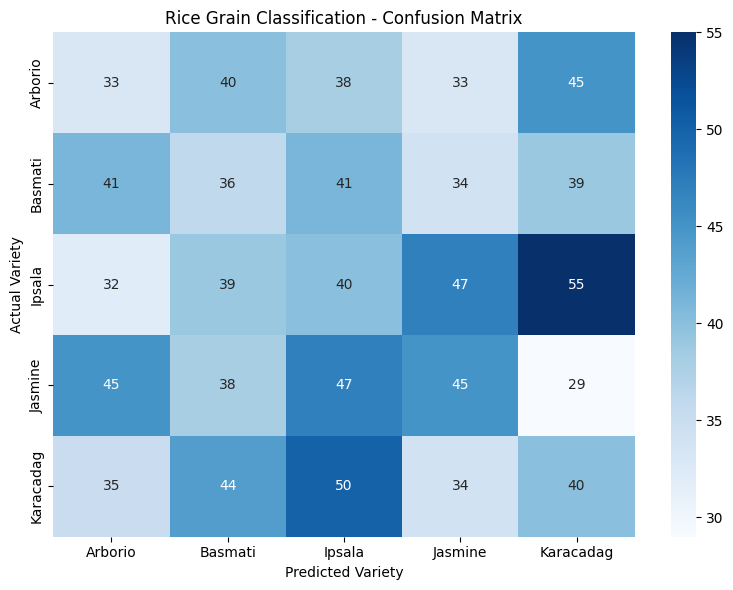

In [15]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# Get true labels
y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

# Get model predictions
y_prob = model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

# Classification report
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Variety")
plt.ylabel("Actual Variety")
plt.title("Rice Grain Classification - Confusion Matrix")
plt.tight_layout()
plt.show()



In [16]:

import tensorflow as tf
import numpy as np

test_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/rice_subset",
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(224, 224),
    batch_size=32,
    shuffle=False
)

print("Validation dataset recreated without shuffling.")


Found 5000 files belonging to 5 classes.
Using 1000 files for validation.
Validation dataset recreated without shuffling.


32/32 ━━━━━━━━━━━━━━━━━━━━ 39s 1s/step
Full validation accuracy: 98.30%

Classification Report:

              precision    recall  f1-score   support

   Karacadag     1.0000    0.9830    0.9914      1000

   micro avg     1.0000    0.9830    0.9914      1000
   macro avg     1.0000    0.9830    0.9914      1000
weighted avg     1.0000    0.9830    0.9914      1000



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


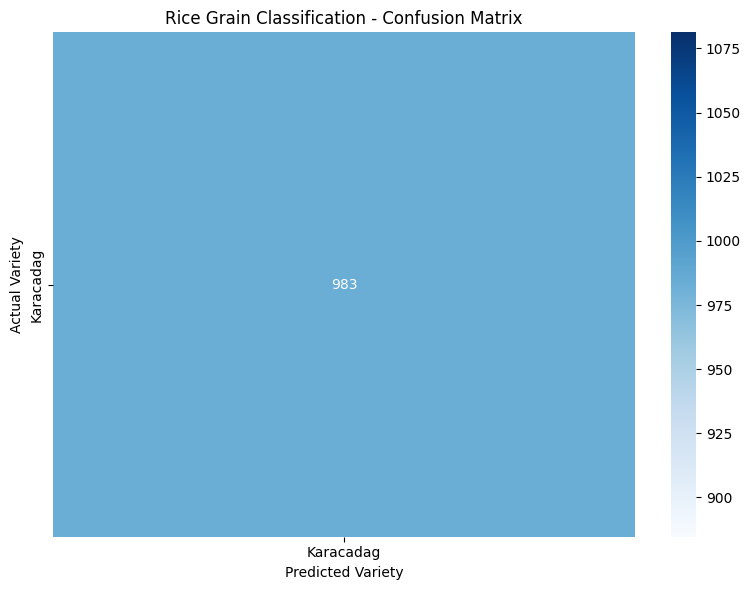

In [18]:

from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Actual labels, in a fixed order
y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

# Predictions in that same order
y_prob = model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

print("Full validation accuracy:",
      f"{np.mean(y_true == y_pred) * 100:.2f}%")

# Determine unique classes present in validation set
unique_classes = np.unique(y_true)
present_class_names = [class_names[i] for i in unique_classes]

print("\nClassification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    labels=unique_classes,
    target_names=present_class_names,
    digits=4
))

cm = confusion_matrix(y_true, y_pred, labels=unique_classes)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=present_class_names,
    yticklabels=present_class_names
)
plt.xlabel("Predicted Variety")
plt.ylabel("Actual Variety")
plt.title("Rice Grain Classification - Confusion Matrix")
plt.tight_layout()
plt.show()

In [19]:

import tensorflow as tf
import numpy as np
import os

data_dir = "/content/rice_subset"
class_names = ["Arborio", "Basmati", "Ipsala", "Jasmine", "Karacadag"]

# Load each class separately so labels are explicit
image_paths = []
labels = []

for label, name in enumerate(class_names):
    folder = os.path.join(data_dir, name)
    files = [
        os.path.join(folder, f)
        for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ]

    image_paths.extend(files)
    labels.extend([label] * len(files))

print("Images per class:")
for i, name in enumerate(class_names):
    print(name, labels.count(i))

print("Total images:", len(image_paths))


Images per class:
Arborio 1000
Basmati 1000
Ipsala 1000
Jasmine 1000
Karacadag 1000
Total images: 5000


32/32 ━━━━━━━━━━━━━━━━━━━━ 39s 1s/step
Accuracy: 98.20%
              precision    recall  f1-score   support

     Arborio     0.9657    0.9850    0.9752       200
     Basmati     0.9754    0.9900    0.9826       200
      Ipsala     1.0000    0.9950    0.9975       200
     Jasmine     0.9846    0.9600    0.9722       200
   Karacadag     0.9849    0.9800    0.9825       200

    accuracy                         0.9820      1000
   macro avg     0.9821    0.9820    0.9820      1000
weighted avg     0.9821    0.9820    0.9820      1000



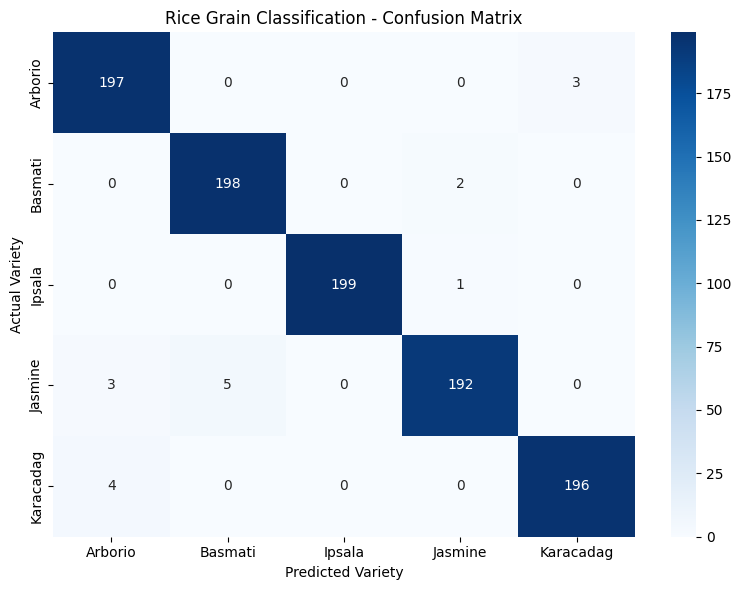

In [20]:

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Create a reproducible 20% evaluation split
paths_train, paths_test, labels_train, labels_test = train_test_split(
    image_paths,
    labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

# Load evaluation images in the same order as their labels
def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, (224, 224))
    return image, label

eval_ds = tf.data.Dataset.from_tensor_slices(
    (paths_test, labels_test)
)
eval_ds = eval_ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
eval_ds = eval_ds.batch(32).prefetch(tf.data.AUTOTUNE)

# Evaluate predictions
y_true = np.array(labels_test)
y_pred = np.argmax(model.predict(eval_ds), axis=1)

print("Accuracy:", f"{np.mean(y_true == y_pred) * 100:.2f}%")
print(classification_report(
    y_true, y_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=class_names,
    digits=4,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3, 4])

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names, yticklabels=class_names
)
plt.xlabel("Predicted Variety")
plt.ylabel("Actual Variety")
plt.title("Rice Grain Classification - Confusion Matrix")
plt.tight_layout()
plt.show()


In [21]:

# Save the trained CNN model
model.save("/content/rice_classifier.keras")

print("Model saved successfully!")


Model saved successfully!


In [22]:

import shutil

drive_model_path = "/content/drive/MyDrive/rice_classifier.keras"

shutil.copy2(
    "/content/rice_classifier.keras",
    drive_model_path
)

print("Model saved to Google Drive:", drive_model_path)


Model saved to Google Drive: /content/drive/MyDrive/rice_classifier.keras


In [24]:

import matplotlib.pyplot as plt

# Combine both training histories
acc = history.history["accuracy"] + history_fast.history["accuracy"]
val_acc = history.history["val_accuracy"] + history_fast.history["val_accuracy"]

loss = history.history["loss"] + history_fast.history["loss"]
val_loss = history.history["val_loss"] + history_fast.history["val_loss"]

epochs = range(1, len(acc) + 1)

# Accuracy graph
plt.figure(figsize=(8, 5))
plt.plot(epochs, acc, label="Training Accuracy")
plt.plot(epochs, val_acc, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Rice Grain Classification - Accuracy")
plt.legend()
plt.grid(True)
plt.savefig("/content/accuracy_graph.png", dpi=300, bbox_inches="tight")
plt.show()

# Loss graph
plt.figure(figsize=(8, 5))
plt.plot(epochs, loss, label="Training Loss")
plt.plot(epochs, val_loss, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Rice Grain Classification - Loss")
plt.legend()
plt.grid(True)
plt.savefig("/content/loss_graph.png", dpi=300, bbox_inches="tight")
plt.show()


NameError: name 'history' is not defined

In [25]:

import tensorflow as tf
import os

model_path = "/content/drive/MyDrive/rice_classifier.keras"

model = tf.keras.models.load_model(model_path)

print("Model loaded successfully!")


Model loaded successfully!


In [26]:

print("history exists:", "history" in globals())
print("history_fast exists:", "history_fast" in globals())


history exists: False
history_fast exists: True


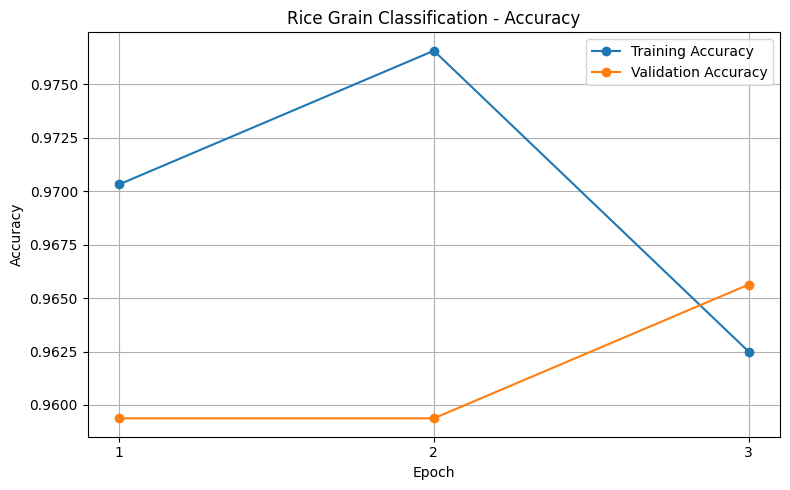

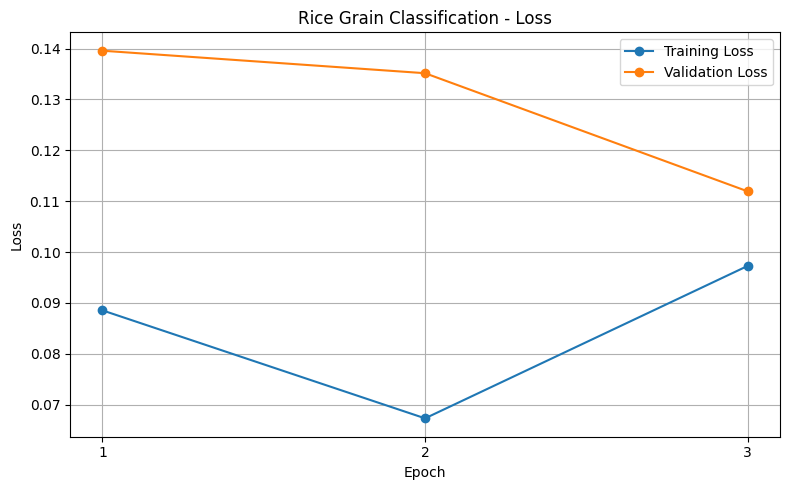

Both graphs generated successfully!


In [27]:

import matplotlib.pyplot as plt

h = history_fast.history
epochs = range(1, len(h["accuracy"]) + 1)

# Accuracy graph
plt.figure(figsize=(8, 5))
plt.plot(epochs, h["accuracy"], marker="o", label="Training Accuracy")
plt.plot(epochs, h["val_accuracy"], marker="o", label="Validation Accuracy")
plt.title("Rice Grain Classification - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("/content/accuracy_graph.png", dpi=300)
plt.show()

# Loss graph
plt.figure(figsize=(8, 5))
plt.plot(epochs, h["loss"], marker="o", label="Training Loss")
plt.plot(epochs, h["val_loss"], marker="o", label="Validation Loss")
plt.title("Rice Grain Classification - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("/content/loss_graph.png", dpi=300)
plt.show()

print("Both graphs generated successfully!")


In [28]:

import shutil

for filename in ["accuracy_graph.png", "loss_graph.png"]:
    shutil.copy2(
        f"/content/{filename}",
        f"/content/drive/MyDrive/{filename}"
    )

print("Both graphs saved to Google Drive!")


Both graphs saved to Google Drive!


CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Arborio     0.9657    0.9850    0.9752       200
     Basmati     0.9754    0.9900    0.9826       200
      Ipsala     1.0000    0.9950    0.9975       200
     Jasmine     0.9846    0.9600    0.9722       200
   Karacadag     0.9849    0.9800    0.9825       200

    accuracy                         0.9820      1000
   macro avg     0.9821    0.9820    0.9820      1000
weighted avg     0.9821    0.9820    0.9820      1000



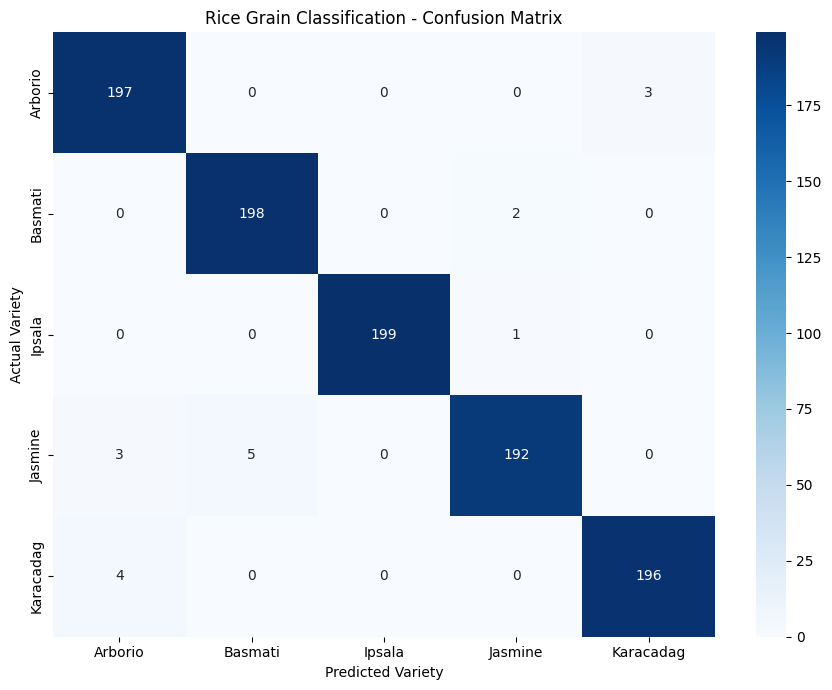

Report and confusion matrix saved to Google Drive!


In [29]:

import os
import shutil
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import classification_report, confusion_matrix

# Class names in the correct order
class_names = ["Arborio", "Basmati", "Ipsala", "Jasmine", "Karacadag"]

# Check that the earlier evaluation results still exist
if "y_true" not in globals() or "y_pred" not in globals():
    raise ValueError(
        "Evaluation predictions are unavailable. Tell me, and we'll recreate them."
    )

# Generate report and confusion matrix
report = classification_report(
    y_true, y_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=class_names,
    digits=4,
    zero_division=0
)

cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3, 4])

print("CLASSIFICATION REPORT")
print(report)

# Save report as a text file
with open("/content/classification_report.txt", "w") as f:
    f.write("PS-11 Rice Grain Variety Classification\n\n")
    f.write(report)

# Save confusion matrix as an image
plt.figure(figsize=(9, 7))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Rice Grain Classification - Confusion Matrix")
plt.xlabel("Predicted Variety")
plt.ylabel("Actual Variety")
plt.tight_layout()
plt.savefig("/content/confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

# Copy results to Google Drive
drive_dir = "/content/drive/MyDrive"

shutil.copy2(
    "/content/classification_report.txt",
    f"{drive_dir}/classification_report.txt"
)
shutil.copy2(
    "/content/confusion_matrix.png",
    f"{drive_dir}/confusion_matrix.png"
)

print("Report and confusion matrix saved to Google Drive!")
